# EEE3032 – Stage 5: Build Bag-of-Visual-Words Histograms

This notebook uses the eight visual vocabularies trained in Stage 4 to convert each image into a fixed-length BoVW histogram.

**What happens here:**
1. Load the saved Stage 4 vocabularies.
2. Extract and cache raw descriptors for the 100 development queries (the gallery caches already exist).
3. Assign every image descriptor to its nearest visual word.
4. Count visual words to create one histogram per image.
5. Fit IDF weights using gallery histograms only.
6. Apply TF-IDF weighting and L2 normalisation to gallery and development histograms.
7. Save the resulting feature matrices for Stage 6 evaluation.


In [ ]:
from pathlib import Path
import sys

# Mount Google Drive when this notebook is running in Google Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3")
DATASET_SOURCE = Path("/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2")

if not (PROJECT_ROOT / "cvpr").is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/.")
if not (PROJECT_ROOT / "visual_search").is_dir():
    raise FileNotFoundError("The visual_search package is missing from PROJECT_ROOT.")

sys.path.insert(0, str(PROJECT_ROOT))
print("Project folder:", PROJECT_ROOT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3


## 2. Import the project functions

The feature extraction, cache, vocabulary and encoding logic lives in `visual_search/`. The notebook calls those reusable functions rather than duplicating their implementation.

In [ ]:
import csv
import numpy as np
import matplotlib.pyplot as plt

from cvpr.dataset import load_split_records
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors
from cvpr.evaluation import evaluate_retrieval, per_category_summary

from visual_search.vocabulary import (
    VOCABULARY_CONFIGS,
    descriptor_cache_folder,
    vocabulary_path,
)
from visual_search.encoding import (
    query_cache_folder,
    cache_query_features,
    load_vocabulary_centres,
    encode_cached_records,
    fit_idf,
    apply_tfidf_l2,
    save_bovw_features,
)

## 3. Load the official split

The official manifest defines 391 gallery images, 100 development queries and 100 final test queries. code loads the split metadata to verify the fixed allocation,

In [ ]:
MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, _test = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)

assert len(gallery) == 391
assert len(dev) == 100
print(f"Gallery images: {len(gallery)}")
print(f"Development queries: {len(dev)}")
print("Final test records loaded only for split verification; not used below.")

Gallery images: 391
Development queries: 100
Final test records loaded only for split verification; not used below.


## 4. Set the experiment parameters

keeping the Stage 4 settings unchanged. All eight configurations use K = 100 and the vocabularies trained with a cap of 200 gallery descriptors per image.

In [ ]:
K = 100
DESCRIPTOR_CAP = 200       # Used for vocabulary training only
RANDOM_SEED = 3032
ASSIGNMENT_BATCH_SIZE = 2048

RESULTS_DIR = PROJECT_ROOT / "results"
FEATURES_DIR = PROJECT_ROOT / "bovw_features" / "stage5_dev"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Configurations: {len(VOCABULARY_CONFIGS)}")
print(f"Vocabulary size: {K}")
print("Descriptor cap during histogram creation: none (use all descriptors)")

Configurations: 8
Vocabulary size: 100
Descriptor cap during histogram creation: none (use all descriptors)


## 5. Check that the Stage 4 vocabularies and gallery caches exist

Each descriptor representation needs its own vocabulary. Grayscale SIFT vocabularies have 128 values per visual word; OpponentSIFT vocabularies have 384.

In [ ]:
from visual_search.cache import feature_cache_path

for config in VOCABULARY_CONFIGS:
    vocab_file = vocabulary_path(
        PROJECT_ROOT, config, K, DESCRIPTOR_CAP, RANDOM_SEED
    )
    if not vocab_file.exists():
        raise FileNotFoundError(f"Missing Stage 4 vocabulary: {vocab_file}")

    cache_folder = descriptor_cache_folder(PROJECT_ROOT, config)
    missing = [
        record.filename
        for index, record in enumerate(gallery)
        if not feature_cache_path(cache_folder, index, record).exists()
    ]
    print(f"{config.name:32s} vocabulary=OK, missing gallery caches={len(missing)}")
    if missing:
        raise FileNotFoundError(f"Missing gallery descriptors for {config.name}: {missing[:3]}")

detected_sift                    vocabulary=OK, missing gallery caches=0
detected_rootsift                vocabulary=OK, missing gallery caches=0
detected_opponentsift            vocabulary=OK, missing gallery caches=0
detected_root_opponentsift       vocabulary=OK, missing gallery caches=0
dense_sift                       vocabulary=OK, missing gallery caches=0
dense_rootsift                   vocabulary=OK, missing gallery caches=0
dense_opponentsift               vocabulary=OK, missing gallery caches=0
dense_root_opponentsift          vocabulary=OK, missing gallery caches=0


## 6. Extract and cache development-query descriptors

Stage 3 extracted descriptors for the gallery. We now need the same four *raw* feature sets for the 100 development queries:

- detected SIFT;
- detected OpponentSIFT;
- dense SIFT;
- dense OpponentSIFT.

RootSIFT is a transformation of an existing descriptor, so it does not require another extraction cache. The standard and Root versions will reuse the same raw descriptors.

The caches are stored in a separate `stage5_queries/dev/` folder so their image indices cannot overwrite or collide with the gallery caches.

In [ ]:
query_feature_sets = [
    ("detected", "sift"),
    ("detected", "opponent"),
    ("dense", "sift"),
    ("dense", "opponent"),
]

query_cache_summary = []
for sampling, representation in query_feature_sets:
    counts = cache_query_features(
        dev,
        PROJECT_ROOT,
        split_name="dev",
        sampling=sampling,
        representation=representation,
        rebuild=False,
        progress_every=25,
    )
    cache_folder = query_cache_folder(
        PROJECT_ROOT, "dev", sampling, representation
    )
    row = {
        "sampling": sampling,
        "representation": representation,
        "images": len(counts),
        "minimum_descriptors": int(np.min(counts)),
        "mean_descriptors": float(np.mean(counts)),
        "maximum_descriptors": int(np.max(counts)),
        "cache_folder": str(cache_folder),
    }
    query_cache_summary.append(row)
    print(
        f"{sampling:8s} {representation:8s}: "
        f"mean={row['mean_descriptors']:.1f}, "
        f"min={row['minimum_descriptors']}, max={row['maximum_descriptors']}"
    )

Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images
detected sift    : mean=459.6, min=18, max=1319
Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images
detected opponent: mean=459.6, min=18, max=1319
Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images
dense    sift    : mean=452.4, min=442, max=494
Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images
dense    opponent: mean=452.4, min=442, max=494


## 7. How one image becomes a BoVW histogram

For one image, the encoder compares every local descriptor with the 100 vocabulary centres and assigns it to its nearest centre. It then counts how many descriptors were assigned to each visual word.

The result is a 100-value histogram. The histogram is fixed length even when images contain different numbers of local descriptors.

The 200-descriptor cap is **not** applied here: all descriptors are counted.

In [ ]:
# Load one detected-SIFT vocabulary and inspect one gallery image.
from visual_search.encoding import build_bovw_histogram
from visual_search.vocabulary import load_image_descriptors
from visual_search.cache import feature_cache_path

sample_config = VOCABULARY_CONFIGS[0]  # detected_sift
sample_vocabulary_file = vocabulary_path(
    PROJECT_ROOT, sample_config, K, DESCRIPTOR_CAP, RANDOM_SEED
)
sample_centres = load_vocabulary_centres(
    sample_vocabulary_file,
    expected_configuration=sample_config.name,
    expected_dimension=sample_config.dimension,
    expected_k=K,
    expected_descriptor_cap=DESCRIPTOR_CAP,
    expected_random_seed=RANDOM_SEED,
)

sample_descriptors = load_image_descriptors(
    PROJECT_ROOT, 0, gallery[0], sample_config
)
sample_histogram = build_bovw_histogram(
    sample_descriptors, sample_centres,
    assignment_batch_size=ASSIGNMENT_BATCH_SIZE,
)

print("Image:", gallery[0].filename)
print("Local descriptors:", sample_descriptors.shape)
print("BoVW histogram:", sample_histogram.shape)
print("Histogram total:", int(sample_histogram.sum()))
print("All local descriptors counted:", sample_histogram.sum() == len(sample_descriptors))
assert sample_histogram.shape == (K,)
assert sample_histogram.sum() == len(sample_descriptors)

Image: 1_10_s.bmp
Local descriptors: (164, 128)
BoVW histogram: (100,)
Histogram total: 164
All local descriptors counted: True


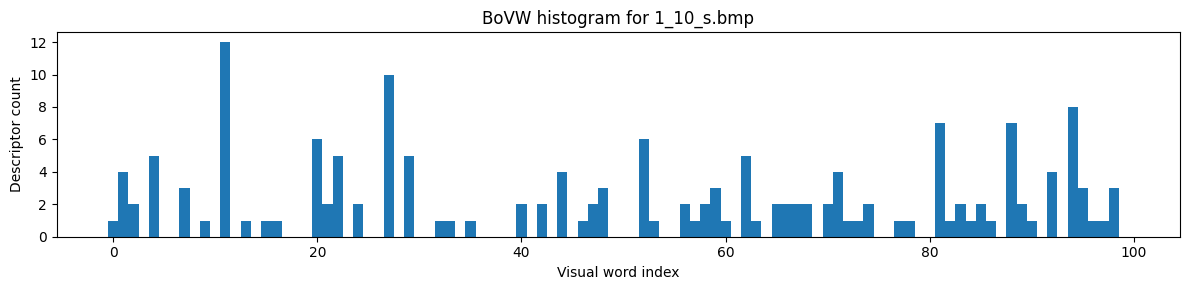

In [ ]:
plt.figure(figsize=(12, 3))
plt.bar(np.arange(K), sample_histogram, width=1.0)
plt.xlabel("Visual word index")
plt.ylabel("Descriptor count")
plt.title(f"BoVW histogram for {gallery[0].filename}")
plt.tight_layout()
plt.show()

## 8. Encode gallery and development images for all eight configurations

For each configuration:

1. Load the matching Stage 4 vocabulary.
2. Load each gallery descriptor cache.
3. Load the matching development-query descriptor cache.
4. Apply RootSIFT when the configuration requires it.
5. Assign **all** descriptors in each image to visual words.
6. Build one raw count histogram per image.
7. Fit IDF weights using gallery histograms only.
8. Apply the same IDF weights to gallery and development histograms.
9. L2-normalise each non-zero image vector.

This keeps development data out of vocabulary and IDF fitting.

In [ ]:
from visual_search.encoding import encode_cached_records

encoding_summary = []

for number, config in enumerate(VOCABULARY_CONFIGS, start=1):
    print(f"\n[{number}/{len(VOCABULARY_CONFIGS)}] {config.name}")

    # Load the vocabulary trained in Stage 4.
    vocab_file = vocabulary_path(
        PROJECT_ROOT, config, K, DESCRIPTOR_CAP, RANDOM_SEED
    )
    centres = load_vocabulary_centres(
        vocab_file,
        expected_configuration=config.name,
        expected_dimension=config.dimension,
        expected_k=K,
        expected_descriptor_cap=DESCRIPTOR_CAP,
        expected_random_seed=RANDOM_SEED,
    )

    # Gallery descriptors use the caches created in Stages 2 and 3.
    gallery_cache = descriptor_cache_folder(PROJECT_ROOT, config)

    # Development descriptors use their own split-specific caches.
    dev_cache = query_cache_folder(
        PROJECT_ROOT, "dev", config.sampling, config.source
    )

    # Convert every image's local descriptors into a 100-bin count histogram.
    gallery_counts = encode_cached_records(
        gallery, gallery_cache, config, centres,
        assignment_batch_size=ASSIGNMENT_BATCH_SIZE,
    )
    dev_counts = encode_cached_records(
        dev, dev_cache, config, centres,
        assignment_batch_size=ASSIGNMENT_BATCH_SIZE,
    )

    assert gallery_counts.shape == (391, K)
    assert dev_counts.shape == (100, K)
    assert np.isfinite(gallery_counts).all()
    assert np.isfinite(dev_counts).all()

    # Fit IDF from gallery images only. Do not use development queries here.
    idf = fit_idf(gallery_counts)

    # Apply the gallery-fitted IDF and L2 normalisation to both splits.
    gallery_features = apply_tfidf_l2(gallery_counts, idf)
    dev_features = apply_tfidf_l2(dev_counts, idf)

    assert gallery_features.shape == (391, K)
    assert dev_features.shape == (100, K)
    assert np.isfinite(gallery_features).all()
    assert np.isfinite(dev_features).all()

    # Every non-zero image vector should have unit L2 length.
    gallery_norms = np.linalg.norm(gallery_features, axis=1)
    dev_norms = np.linalg.norm(dev_features, axis=1)
    assert np.allclose(gallery_norms[gallery_norms > 0], 1.0, atol=1e-5)
    assert np.allclose(dev_norms[dev_norms > 0], 1.0, atol=1e-5)

    # Save the feature matrices and IDF so later stages can reuse them.
    feature_file = FEATURES_DIR / f"{config.name}_K{K}.npz"
    save_bovw_features(
        feature_file,
        configuration=config.name,
        vocabulary_file=vocab_file,
        gallery_records=gallery,
        query_records=dev,
        gallery_features=gallery_features,
        query_features=dev_features,
        idf=idf,
        k=K,
    )

    row = {
        "configuration": config.name,
        "descriptor_dimension": config.dimension,
        "K": K,
        "gallery_matrix": str(gallery_features.shape),
        "development_matrix": str(dev_features.shape),
        "gallery_zero_histograms": int(np.sum(gallery_counts.sum(axis=1) == 0)),
        "development_zero_histograms": int(np.sum(dev_counts.sum(axis=1) == 0)),
        "gallery_assignments": int(gallery_counts.sum()),
        "development_assignments": int(dev_counts.sum()),
        "idf_min": float(idf.min()),
        "idf_max": float(idf.max()),
        "feature_file": str(feature_file),
    }
    encoding_summary.append(row)

    print("  Gallery features:", gallery_features.shape)
    print("  Development features:", dev_features.shape)
    print("  Gallery images with empty histograms:", row["gallery_zero_histograms"])
    print("  Development images with empty histograms:", row["development_zero_histograms"])
    print("  Saved:", feature_file)


[1/8] detected_sift
  Gallery features: (391, 100)
  Development features: (100, 100)
  Gallery images with empty histograms: 0
  Development images with empty histograms: 0
  Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/bovw_features/stage5_dev/detected_sift_K100.npz

[2/8] detected_rootsift
  Gallery features: (391, 100)
  Development features: (100, 100)
  Gallery images with empty histograms: 0
  Development images with empty histograms: 0
  Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/bovw_features/stage5_dev/detected_rootsift_K100.npz

[3/8] detected_opponentsift
  Gallery features: (391, 100)
  Development features: (100, 100)
  Gallery images with empty histograms: 0
  Development images with empty histograms: 0
  Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/bovw_features/stage5_dev/detected_opponentsift_K100.npz

[4/8] detected_root_opponentsift
  Gallery features: (391, 100)
  Develo

## 9. Save the Stage 5 summary

The summary records the dimensions, number of descriptor assignments, empty histograms and IDF range for each configuration.

In [ ]:
summary_file = RESULTS_DIR / "stage5_encoding_summary.csv"
with summary_file.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(encoding_summary[0].keys()))
    writer.writeheader()
    writer.writerows(encoding_summary)

query_summary_file = RESULTS_DIR / "stage5_dev_descriptor_summary.csv"
with query_summary_file.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(query_cache_summary[0].keys()))
    writer.writeheader()
    writer.writerows(query_cache_summary)

print("Encoding summary:", summary_file)
print("Development descriptor summary:", query_summary_file)

Encoding summary: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage5_encoding_summary.csv
Development descriptor summary: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage5_dev_descriptor_summary.csv


## 10. Review the eight encoded feature sets

Every gallery matrix should have 391 rows and every development matrix should have 100 rows. All eight configurations use K = 100, so each image is represented by 100 values.

In [ ]:
for row in encoding_summary:
    print(
        f"{row['configuration']:32s} "
        f"gallery={row['gallery_matrix']:12s} "
        f"dev={row['development_matrix']:12s} "
        f"empty={row['gallery_zero_histograms']}/{row['development_zero_histograms']}"
    )

assert len(encoding_summary) == 8
assert all(row["gallery_matrix"] == "(391, 100)" for row in encoding_summary)
assert all(row["development_matrix"] == "(100, 100)" for row in encoding_summary)
print("\nAll eight configurations passed the Stage 5 shape checks.")

detected_sift                    gallery=(391, 100)   dev=(100, 100)   empty=0/0
detected_rootsift                gallery=(391, 100)   dev=(100, 100)   empty=0/0
detected_opponentsift            gallery=(391, 100)   dev=(100, 100)   empty=0/0
detected_root_opponentsift       gallery=(391, 100)   dev=(100, 100)   empty=0/0
dense_sift                       gallery=(391, 100)   dev=(100, 100)   empty=0/0
dense_rootsift                   gallery=(391, 100)   dev=(100, 100)   empty=0/0
dense_opponentsift               gallery=(391, 100)   dev=(100, 100)   empty=0/0
dense_root_opponentsift          gallery=(391, 100)   dev=(100, 100)   empty=0/0

All eight configurations passed the Stage 5 shape checks.
